In [1]:
import os, sys
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
os.environ['OMP_NUM_THREADS'] = '1'
import torch
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device : {device}')
if device.type == 'cuda':
    print(f'GPU    : {torch.cuda.get_device_name(0)}')


Device : cuda
GPU    : NVIDIA GeForce RTX 5060 Laptop GPU


In [2]:
import os

def is_colab():
    try: import google.colab; return True
    except ImportError: return False

if is_colab():
    from google.colab import drive
    drive.mount('/content/drive')
    COLAB_BASE = '/content/drive/MyDrive/Rakuten'
    import subprocess
    subprocess.run(['pip', 'install', '-q', 'sentence-transformers', 'lightgbm'], check=False)
else:
    COLAB_BASE = None
print('Colab OK' if is_colab() else 'Local')


Local


In [3]:
LOCAL_BASE = r'C:/Users/veyss/Nouveau dossier/nov25_alt1_mle_rakuten'
BASE = COLAB_BASE if ('COLAB_BASE' in dir() and COLAB_BASE) else LOCAL_BASE
print(f'BASE : {BASE}')


BASE : C:/Users/veyss/Nouveau dossier/nov25_alt1_mle_rakuten


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle, time
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import scipy.sparse as sp
from sklearn.preprocessing import normalize
from sklearn.linear_model import LogisticRegression
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import f1_score, classification_report

import torchvision.transforms as T
import torchvision.models as models
from tqdm import tqdm
from PIL import Image


In [5]:
SPLIT_DIR     = os.path.join(BASE, 'data', 'split')
PROCESSED_DIR = os.path.join(BASE, 'data', 'processed')
MODELS_DIR    = os.path.join(BASE, 'models')
CACHE_DIR     = PROCESSED_DIR
os.makedirs(MODELS_DIR, exist_ok=True)


In [6]:
train_split = pd.read_csv(os.path.join(SPLIT_DIR, 'train.csv'))
val_split   = pd.read_csv(os.path.join(SPLIT_DIR, 'val.csv'))
test_split  = pd.read_csv(os.path.join(SPLIT_DIR, 'test.csv'))

y_train = train_split['label'].values.astype(int)
y_val   = val_split['label'].values.astype(int)
y_test  = test_split['label'].values.astype(int)

with open(os.path.join(MODELS_DIR, 'label_encoder.pkl'), 'rb') as f:
    le = pickle.load(f)
class_names = [str(c) for c in le.inverse_transform(range(27))]
print(f'Splits : train={len(train_split):,} | val={len(val_split):,} | test={len(test_split):,}')


Splits : train=59,185 | val=12,993 | test=12,738


In [7]:
NEEDED_COL = "text_combined_raw"

if NEEDED_COL not in train_split.columns:
    print(f"COLONNE MANQUANTE : '{NEEDED_COL}' absente de train.csv")
    print("Solution : relancer la cellule 107 dans 01_baseline.ipynb")
    print("           puis re-uploader les CSVs sur Drive")
else:
    texts_train = train_split[NEEDED_COL].fillna("").tolist()
    texts_val   = val_split[NEEDED_COL].fillna("").tolist()
    texts_test  = test_split[NEEDED_COL].fillna("").tolist()
    print(f"Textes charges depuis split CSVs :")
    print(f"  train={len(texts_train):,} | val={len(texts_val):,} | test={len(texts_test):,}")
    print(f"  Exemple : {texts_train[0][:120]}")

Textes charges depuis split CSVs :
  train=59,185 | val=12,993 | test=12,738
  Exemple : plaque metal 30x20cm style émaillé aston martin db5 james bond


### Etape 1 — Features texte (SentenceTransformer)

> Reutilise le cache de `02_st_experiments`. Si absent, recalcule.

In [8]:
from sentence_transformers import SentenceTransformer

ST_MODEL = "intfloat/multilingual-e5-large" #"intfloat/multilingual-e5-base" # "paraphrase-multilingual-mpnet-base-v2"
ST_TRAIN = os.path.join(CACHE_DIR, f"X_st_{ST_MODEL[9:]}_train.npy")
ST_VAL   = os.path.join(CACHE_DIR, f"X_st_{ST_MODEL[9:]}_val.npy")
ST_TEST  = os.path.join(CACHE_DIR, f"X_st_{ST_MODEL[9:]}_test.npy")

if os.path.exists(ST_TRAIN) and os.path.exists(ST_VAL) and os.path.exists(ST_TEST):
    X_txt_train = np.load(ST_TRAIN)
    X_txt_val   = np.load(ST_VAL)
    X_txt_test  = np.load(ST_TEST)
    print("Embeddings ST charges depuis cache.")
else:
    print(f"Calcul embeddings ST ({ST_MODEL})...")
    print("~20 min CPU | ~2 min GPU — progression ci-dessous")
    st_model = SentenceTransformer(ST_MODEL, device=str(device),model_kwargs={"torch_dtype": "float16"})
    X_txt_train = st_model.encode(
        texts_train, batch_size=64, show_progress_bar=True,
        normalize_embeddings=True, convert_to_numpy=True)
    X_txt_val   = st_model.encode(
        texts_val,   batch_size=64, show_progress_bar=True,
        normalize_embeddings=True, convert_to_numpy=True)
    X_txt_test  = st_model.encode(
        texts_test,  batch_size=64, show_progress_bar=True,
        normalize_embeddings=True, convert_to_numpy=True)
    np.save(ST_TRAIN, X_txt_train)
    np.save(ST_VAL,   X_txt_val)
    np.save(ST_TEST,  X_txt_test)
    print("Embeddings sauvegardes dans data/processed/")

print(f"ST embeddings : train={X_txt_train.shape} | val={X_txt_val.shape} | test={X_txt_test.shape}")
print(f"Norme L2 (verification) : {np.linalg.norm(X_txt_train[0]):.4f} (doit etre ~1.0)")


c:\Users\veyss\anaconda3\envs\rakuten_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Embeddings ST charges depuis cache.
ST embeddings : train=(59185, 1024) | val=(12993, 1024) | test=(12738, 1024)
Norme L2 (verification) : 1.0000 (doit etre ~1.0)


In [9]:
# ── TF-IDF sparse (pour clf_text sklearn) ──────────────────────────
import scipy.sparse as sp

TFIDF_TRAIN_PATH = os.path.join(PROCESSED_DIR, 'X_tfidf_train.npz')
if os.path.exists(TFIDF_TRAIN_PATH):
    X_tfidf_train = sp.load_npz(TFIDF_TRAIN_PATH)
    X_tfidf_val   = sp.load_npz(os.path.join(PROCESSED_DIR, 'X_tfidf_val.npz'))
    X_tfidf_test  = sp.load_npz(os.path.join(PROCESSED_DIR, 'X_tfidf_test.npz'))
    print(f'TF-IDF charge : train={X_tfidf_train.shape}')
else:
    X_tfidf_train = X_tfidf_val = X_tfidf_test = None
    print('TF-IDF introuvable — relancer notebook 01')


TF-IDF charge : train=(59185, 50000)


In [10]:
# ── Vrai c-TF-IDF : IDF au niveau classe, pas document ──────────────
# 1. Mega-document par classe = concat de tous les textes de la classe
# 2. TF-IDF entraine sur ces 27 mega-docs → IDF penalise les mots
#    communs a TOUTES les classes (ex: 'produit'), pas juste communs
#    dans le corpus global
# 3. Similarite cosinus produit <-> signature de classe → (n, 27)

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize as sp_norm

CTFIDF_CACHE    = os.path.join(CACHE_DIR, 'X_ctfidf_train.npy')
CTFIDF_VEC_PATH = os.path.join(MODELS_DIR, 'ctfidf_vectorizer.pkl')

if os.path.exists(CTFIDF_CACHE):
    X_ctfidf_train = np.load(CTFIDF_CACHE)
    X_ctfidf_val   = np.load(os.path.join(CACHE_DIR, 'X_ctfidf_val.npy'))
    X_ctfidf_test  = np.load(os.path.join(CACHE_DIR, 'X_ctfidf_test.npy'))
    print(f'c-TF-IDF charge depuis cache : {X_ctfidf_train.shape}')
else:
    print('Calcul c-TF-IDF (mega-documents par classe)...')

    # 1. Un mega-document par classe
    class_mega_docs = [''] * 27
    for text, label in zip(texts_train, y_train):
        class_mega_docs[label] += ' ' + str(text)

    # 2. TF-IDF sur les 27 mega-docs : IDF = log(1 + 27 / classes_avec_mot)
    ctfidf_vec = TfidfVectorizer(max_features=50000, sublinear_tf=True, min_df=1)
    C      = ctfidf_vec.fit_transform(class_mega_docs)  # (27, vocab)
    C_norm = sp_norm(C, norm='l2')                       # signature L2 de chaque classe

    # 3. Transformer chaque produit puis similarite cosinus avec chaque classe
    def _ctfidf_sim(texts):
        X = ctfidf_vec.transform(texts)           # (n, vocab) — IDF classe
        X = sp_norm(X, norm='l2')
        return (X @ C_norm.T).toarray().astype('float32')  # (n, 27)

    X_ctfidf_train = _ctfidf_sim(texts_train)
    X_ctfidf_val   = _ctfidf_sim(texts_val)
    X_ctfidf_test  = _ctfidf_sim(texts_test)

    np.save(CTFIDF_CACHE,                                X_ctfidf_train)
    np.save(os.path.join(CACHE_DIR,'X_ctfidf_val.npy'),   X_ctfidf_val)
    np.save(os.path.join(CACHE_DIR,'X_ctfidf_test.npy'),  X_ctfidf_test)
    with open(CTFIDF_VEC_PATH,'wb') as _f: pickle.dump(ctfidf_vec, _f)
    print(f'c-TF-IDF calcule : {X_ctfidf_train.shape}')
    print(f'  range [{X_ctfidf_train.min():.3f}, {X_ctfidf_train.max():.3f}]')

# ── Concatenation : TF-IDF sparse + c-TF-IDF dense + e5 dense ───────
if X_tfidf_train is not None:
    X_txt_train_full = sp.hstack([
        X_tfidf_train,
        sp.csr_matrix(X_ctfidf_train),
        sp.csr_matrix(X_txt_train.astype('float32'))])
    X_txt_val_full   = sp.hstack([
        X_tfidf_val,
        sp.csr_matrix(X_ctfidf_val),
        sp.csr_matrix(X_txt_val.astype('float32'))])
    X_txt_test_full  = sp.hstack([
        X_tfidf_test,
        sp.csr_matrix(X_ctfidf_test),
        sp.csr_matrix(X_txt_test.astype('float32'))])
    print(f'Texte complet (TF-IDF + c-TF-IDF + e5) : {X_txt_train_full.shape}')
else:
    X_txt_train_full = sp.csr_matrix(X_txt_train.astype('float32'))
    X_txt_val_full   = sp.csr_matrix(X_txt_val.astype('float32'))
    X_txt_test_full  = sp.csr_matrix(X_txt_test.astype('float32'))
    print('Fallback : e5 seul')


c-TF-IDF charge depuis cache : (59185, 27)
Texte complet (TF-IDF + c-TF-IDF + e5) : (59185, 51051)


### Etape 2 — CONFIG

In [ ]:
EXPERIMENT = {
    'name'        : 'exp_dino_ft_ctfidf_st_nocrop',
    'description' : 'Late fusion : c-TF-IDF + ST + dinov2 768d fine-tune 2 blocs (stacking probas)',
    'img_backbone': 'dinov2',
    'img_dim'     : 768,
    'img_frozen'  : True,
    'use_crop'    : False,
    'classifier'  : 'mlp',
    'C_text'      : 1.0,
    'C_meta'      : 1.0,
    'max_iter'    : 300,
}
print(f"Experience : {EXPERIMENT['name']}")

In [12]:
# ── Mise a jour SPLIT_DIR selon use_crop ─────────────────────────────
if not EXPERIMENT.get('use_crop', True):
    SPLIT_DIR = os.path.join(BASE, 'data', 'split_no_crop')
    print(f'Mode : images NON croppees -> {SPLIT_DIR}')
else:
    SPLIT_DIR = os.path.join(BASE, 'data', 'split')
    print(f'Mode : images croppees -> {SPLIT_DIR}')

# Recharger les splits CSV avec le bon SPLIT_DIR
train_split = pd.read_csv(os.path.join(SPLIT_DIR, 'train.csv'))
val_split   = pd.read_csv(os.path.join(SPLIT_DIR, 'val.csv'))
test_split  = pd.read_csv(os.path.join(SPLIT_DIR, 'test.csv'))
y_train = train_split['label'].values.astype(int)
y_val   = val_split['label'].values.astype(int)
y_test  = test_split['label'].values.astype(int)
print(f'Splits recharges : train={len(train_split):,} | val={len(val_split):,} | test={len(test_split):,}')


Mode : images NON croppees -> C:/Users/veyss/Nouveau dossier/nov25_alt1_mle_rakuten\data\split_no_crop
Splits recharges : train=59,185 | val=12,993 | test=12,738


### Etape 3 — Features image (ResNet backbone)

In [13]:
backbone_name = EXPERIMENT["img_backbone"]

if backbone_name == "resnet18":
    backbone = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    backbone.fc = torch.nn.Identity()
    img_transform = T.Compose([
        T.Resize((224,224)), T.ToTensor(),
        T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])])

elif backbone_name == "resnet50":
    backbone = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
    backbone.fc = torch.nn.Identity()
    img_transform = T.Compose([
        T.Resize((224,224)), T.ToTensor(),
        T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])])

elif backbone_name == "clip":
    from transformers import CLIPModel, CLIPProcessor
    _clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")
    backbone = _clip.vision_model
    img_transform = T.Compose([
        T.Resize((224,224)), T.ToTensor(),
        T.Normalize([0.48145466,0.4578275,0.40821073],
                    [0.26862954,0.26130258,0.27577711])])

elif backbone_name == "dinov2":
    from transformers import AutoModel
    backbone = AutoModel.from_pretrained("facebook/dinov2-base")
    img_transform = T.Compose([
        T.Resize((224,224)), T.ToTensor(),
        T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])])

if EXPERIMENT["img_frozen"]:
    for p in backbone.parameters(): p.requires_grad = False
backbone.eval().to(device)
print(f"Backbone : {backbone_name} | frozen={EXPERIMENT['img_frozen']} | dim={EXPERIMENT['img_dim']}")


Backbone : dinov2 | frozen=True | dim=768


In [14]:
class ImageDataset(Dataset):
    def __init__(self, df, img_dir, transform):
        self.records = df[['image_name','label']].reset_index(drop=True)
        self.img_dir = img_dir
        self.transform = transform
    def __len__(self): return len(self.records)
    def __getitem__(self, idx):
        row  = self.records.iloc[idx]
        path = os.path.join(self.img_dir, row['image_name'])
        try:
            img = Image.open(path).convert('RGB')
            if self.transform: img = self.transform(img)
        except Exception:
            img = torch.zeros(3, 224, 224)
        return img, int(row['label'])

def extract_img_features(df, split_name):
    cache = os.path.join(CACHE_DIR, f"X_img_{EXPERIMENT['img_backbone']}_{split_name}.npy")
    if os.path.exists(cache):
        arr = np.load(cache)
        print(f'{split_name} : cache charge {arr.shape}')
        return arr
    loader = DataLoader(
        ImageDataset(df, os.path.join(SPLIT_DIR, split_name), img_transform),
        batch_size=64, shuffle=False, num_workers=0)
    feats = []
    with torch.no_grad():
        for imgs, _ in tqdm(loader, desc=split_name):
            imgs = imgs.to(device)
            if backbone_name == "clip":
                out = backbone(pixel_values=imgs).pooler_output
            elif backbone_name == "dinov2":
                out = backbone(pixel_values=imgs).last_hidden_state[:, 0, :]
            else:
                out = backbone(imgs)
            feats.append(out.cpu().numpy())
    X = np.vstack(feats)
    np.save(cache, X)
    return X

X_img_train = extract_img_features(train_split, 'train')
X_img_val   = extract_img_features(val_split,   'val')
X_img_test  = extract_img_features(test_split,  'test')
X_img_train_n = normalize(X_img_train)
X_img_val_n   = normalize(X_img_val)
X_img_test_n  = normalize(X_img_test)
print(f'Image : train={X_img_train.shape} | val={X_img_val.shape}')


train : cache charge (59185, 768)
val : cache charge (12993, 768)
test : cache charge (12738, 768)
Image : train=(59185, 768) | val=(12993, 768)


### Etape 4 — Niveau 1 : classifieurs texte et image separement

In [15]:
import torch.nn as nn
import torch.optim as optim

N_CLASSES = 27

class _LinearHead(nn.Module):
    """Tete de classification lineaire sur embeddings geles."""
    def __init__(self, in_dim):
        super().__init__()
        self.fc = nn.Linear(in_dim, N_CLASSES)
    def forward(self, x):
        return self.fc(x)


def train_head(X_tr_np, y_tr_np, X_va_np, y_va_np,
               ckpt_path, name, n_epochs=40, lr=1e-3, batch_size=256):
    """Entraine une tete lineaire sur des embeddings fixes."""
    in_dim = X_tr_np.shape[1]
    model  = _LinearHead(in_dim).to(device)

    if os.path.exists(ckpt_path):
        model.load_state_dict(torch.load(ckpt_path, map_location=device))
        preds = model(torch.tensor(X_va_np, dtype=torch.float32).to(device)).argmax(1).cpu().numpy()
        print(f"{name}: checkpoint charge | val_F1={f1_score(y_va_np, preds, average='macro'):.4f}")
        return model

    X_tr = torch.tensor(X_tr_np, dtype=torch.float32)
    y_tr = torch.tensor(y_tr_np, dtype=torch.long)
    X_va = torch.tensor(X_va_np, dtype=torch.float32).to(device)

    loader    = DataLoader(torch.utils.data.TensorDataset(X_tr, y_tr),
                           batch_size=batch_size, shuffle=True)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs)

    best_f1, no_improve, patience = 0.0, 0, 5
    for epoch in range(n_epochs):
        model.train()
        total_loss, n = 0.0, 0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(yb)
            n += len(yb)
        scheduler.step()

        model.eval()
        with torch.no_grad():
            preds = model(X_va).argmax(1).cpu().numpy()
        val_f1 = f1_score(y_va_np, preds, average="macro")

        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f"  {name} | epoch {epoch+1:3d} | loss={total_loss/n:.4f} | val_F1={val_f1:.4f}")

        if val_f1 > best_f1:
            best_f1, no_improve = val_f1, 0
            torch.save(model.state_dict(), ckpt_path)
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f"  Early stop epoch {epoch+1}")
                break

    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    print(f"{name}: meilleur val_F1 = {best_f1:.4f}")
    return model


def get_probas(model, X_np, batch_size=512):
    """Probas softmax (n, 27) depuis un _LinearHead."""
    model.eval()
    X_t = torch.tensor(X_np, dtype=torch.float32)
    out = []
    with torch.no_grad():
        for i in range(0, len(X_t), batch_size):
            xb = X_t[i:i + batch_size].to(device)
            out.append(torch.softmax(model(xb), dim=1).cpu().numpy())
    return np.vstack(out)


In [16]:
# ── Classifieur texte : sklearn LogReg sur TF-IDF sparse + e5 dense ─
CACHE_CLF_TEXT = os.path.join(MODELS_DIR, f"clf1_text_{EXPERIMENT['name']}.pkl")

if os.path.exists(CACHE_CLF_TEXT):
    with open(CACHE_CLF_TEXT, 'rb') as f: clf_text = pickle.load(f)
    print('clf_text charge depuis cache')
else:
    print('Entrainement clf_text (TF-IDF + e5 -> LogReg)...')
    clf_text = LogisticRegression(
        C=EXPERIMENT['C_text'], max_iter=10,
        class_weight='balanced', solver='saga',
        warm_start=True, n_jobs=-1, random_state=42)
    for n_iter in [10, 25, 50, 100, 200,  300]:
        clf_text.set_params(max_iter=n_iter)
        clf_text.fit(X_txt_train_full, y_train)
        f1_va = f1_score(y_val, clf_text.predict(X_txt_val_full), average='macro')
        print(f'  iter={n_iter:4d}  val_F1={f1_va:.4f}')
    with open(CACHE_CLF_TEXT, 'wb') as f: pickle.dump(clf_text, f)

f1_text_val = f1_score(y_val, clf_text.predict(X_txt_val_full), average='macro')
print(f'clf_text  val F1 = {f1_text_val:.4f}')


clf_text charge depuis cache
clf_text  val F1 = 0.8340


In [ ]:
# ── Image : DINOv2 fine-tune (2 derniers blocs) + MLP head ──────────
import torch.nn as nn
import torch.optim as optim

N_CLASSES  = 27
FT_EPOCHS  = 10
CKPT_IMG   = os.path.join(MODELS_DIR, f"nn_img_ft_{EXPERIMENT['name']}.pth")

class DINOv2Classifier(nn.Module):
    def __init__(self, backbone, dim):
        super().__init__()
        self.backbone = backbone
        self.head = nn.Sequential(
            nn.Linear(dim, 256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, N_CLASSES))
    def forward(self, pixel_values):
        feat = self.backbone(pixel_values=pixel_values).last_hidden_state[:, 0, :]
        return self.head(feat)

clf_img_ft = DINOv2Classifier(backbone, EXPERIMENT['img_dim']).to(device)

if os.path.exists(CKPT_IMG):
    clf_img_ft.load_state_dict(torch.load(CKPT_IMG, map_location=device))
    print(f'Image FT charge depuis checkpoint')
else:
    # Geler tout, degeler les 2 derniers blocs encoder
    for p in clf_img_ft.backbone.parameters(): p.requires_grad = False
    for p in clf_img_ft.backbone.encoder.layer[-2:].parameters(): p.requires_grad = True

    train_loader_ft = DataLoader(
        ImageDataset(train_split, os.path.join(SPLIT_DIR, 'train'), img_transform),
        batch_size=32, shuffle=True,  num_workers=0, pin_memory=(device.type=='cuda'))
    val_loader_ft = DataLoader(
        ImageDataset(val_split,   os.path.join(SPLIT_DIR, 'val'),   img_transform),
        batch_size=32, shuffle=False, num_workers=0, pin_memory=(device.type=='cuda'))

    optimizer = optim.AdamW([
        {'params': clf_img_ft.backbone.encoder.layer[-2:].parameters(), 'lr': 1e-5},
        {'params': clf_img_ft.head.parameters(),                        'lr': 1e-3},
    ], weight_decay=1e-4)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=FT_EPOCHS)
    criterion = nn.CrossEntropyLoss()

    best_f1, no_improve, patience = 0.0, 0, 3
    for epoch in range(FT_EPOCHS):
        clf_img_ft.train()
        total_loss, n = 0.0, 0
        for imgs, labels in tqdm(train_loader_ft, desc=f'FT {epoch+1}/{FT_EPOCHS}'):
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(clf_img_ft(imgs), labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(labels)
            n += len(labels)
        scheduler.step()

        clf_img_ft.eval()
        preds_ft, true_ft = [], []
        with torch.no_grad():
            for imgs, labels in val_loader_ft:
                preds_ft.extend(clf_img_ft(imgs.to(device)).argmax(1).cpu().numpy())
                true_ft.extend(labels.numpy())
        val_f1 = f1_score(true_ft, preds_ft, average='macro')
        print(f'  Epoch {epoch+1}: loss={total_loss/n:.4f}  val_F1={val_f1:.4f}')

        if val_f1 > best_f1:
            best_f1, no_improve = val_f1, 0
            torch.save(clf_img_ft.state_dict(), CKPT_IMG)
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f'  Early stop epoch {epoch+1}')
                break

    clf_img_ft.load_state_dict(torch.load(CKPT_IMG, map_location=device))
    print(f'Fine-tuning termine | meilleur val_F1 = {best_f1:.4f}')

clf_img_ft.eval()

def get_img_probas(model, df, split_name, batch_size=64):
    model.eval()
    loader = DataLoader(
        ImageDataset(df, os.path.join(SPLIT_DIR, split_name), img_transform),
        batch_size=batch_size, shuffle=False, num_workers=0)
    out = []
    with torch.no_grad():
        for imgs, _ in loader:
            out.append(torch.softmax(model(imgs.to(device)), dim=1).cpu().numpy())
    return np.vstack(out)

### Etape 5 — Extraction des probabilites (niveau 1 -> niveau 2)

In [ ]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# ── Probas niveau 1 : cache pour eviter recalcul (lent) ────────────
_pfx = os.path.join(CACHE_DIR, f"probas_{EXPERIMENT['name']}")
P_TEXT_CACHE = (_pfx + '_text_train.npy', _pfx + '_text_val.npy', _pfx + '_text_test.npy')
P_IMG_CACHE  = (_pfx + '_img_train.npy',  _pfx + '_img_val.npy',  _pfx + '_img_test.npy')

if all(os.path.exists(p) for p in P_TEXT_CACHE):
    P_text_train, P_text_val, P_text_test = (np.load(p) for p in P_TEXT_CACHE)
    print(f'Probas texte chargees depuis cache')
else:
    print('Calcul probas texte...')
    P_text_train = clf_text.predict_proba(X_txt_train_full)
    P_text_val   = clf_text.predict_proba(X_txt_val_full)
    P_text_test  = clf_text.predict_proba(X_txt_test_full)
    for p, arr in zip(P_TEXT_CACHE, [P_text_train, P_text_val, P_text_test]):
        np.save(p, arr)
    print(f'Probas texte sauvegardees')

if all(os.path.exists(p) for p in P_IMG_CACHE):
    P_img_train, P_img_val, P_img_test = (np.load(p) for p in P_IMG_CACHE)
    print(f'Probas image chargees depuis cache')
else:
    print('Calcul probas image (DINOv2 fine-tune forward pass sur 3 splits)...')
    P_img_train = get_img_probas(clf_img_ft, train_split, 'train')
    P_img_val   = get_img_probas(clf_img_ft, val_split,   'val')
    P_img_test  = get_img_probas(clf_img_ft, test_split,  'test')
    for p, arr in zip(P_IMG_CACHE, [P_img_train, P_img_val, P_img_test]):
        np.save(p, arr)
    print(f'Probas image sauvegardees')

# ── Features extra ────────────────────────────────────────────────────
if not EXPERIMENT.get('use_crop', True):
    EXTRA_COLS = [c for c in ['has_desc'] if c in train_split.columns]
else:
    EXTRA_COLS = [c for c in ['has_desc', 'zoom_ratio'] if c in train_split.columns]

if EXTRA_COLS:
    scaler = StandardScaler()
    X_extra_train = scaler.fit_transform(train_split[EXTRA_COLS].fillna(0))
    X_extra_val   = scaler.transform(val_split[EXTRA_COLS].fillna(0))
    X_extra_test  = scaler.transform(test_split[EXTRA_COLS].fillna(0))
    print(f'Extra numeriques : {EXTRA_COLS}')
else:
    X_extra_train = np.empty((len(train_split), 0))
    X_extra_val   = np.empty((len(val_split),   0))
    X_extra_test  = np.empty((len(test_split),  0))

if 'lang' in train_split.columns:
    ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
    X_lang_train = ohe.fit_transform(train_split[['lang']].fillna('fr'))
    X_lang_val   = ohe.transform(val_split[['lang']].fillna('fr'))
    X_lang_test  = ohe.transform(test_split[['lang']].fillna('fr'))
else:
    X_lang_train = np.empty((len(train_split), 0))
    X_lang_val   = np.empty((len(val_split),   0))
    X_lang_test  = np.empty((len(test_split),  0))

# ── Concatenation meta ────────────────────────────────────────────────
X_meta_train = np.hstack([P_text_train, P_img_train, X_ctfidf_train, X_extra_train, X_lang_train])
X_meta_val   = np.hstack([P_text_val,   P_img_val,   X_ctfidf_val,   X_extra_val,   X_lang_val])
X_meta_test  = np.hstack([P_text_test,  P_img_test,  X_ctfidf_test,  X_extra_test,  X_lang_test])
print(f'Meta features : {X_meta_train.shape}')
print(f'  P_text(27) + P_img(27) + c-TF-IDF(27) + extra({X_extra_train.shape[1]}) + lang({X_lang_train.shape[1]})')

### Etape 6a — Niveau 2 : meta-classifieur LogReg sur les probas

In [63]:
from sklearn.neural_network import MLPClassifier

CACHE_META = os.path.join(MODELS_DIR, f"clf_meta_{EXPERIMENT['name']}.pkl")
if os.path.exists(CACHE_META):
    with open(CACHE_META,'rb') as f: clf_meta = pickle.load(f)
    # Verifier coherence features
    if hasattr(clf_meta, 'n_features_in_') and clf_meta.n_features_in_ != X_meta_train.shape[1]:
        print(f'Cache invalide : {clf_meta.n_features_in_} features vs {X_meta_train.shape[1]} actuels — reentranement')
        os.remove(CACHE_META)
        clf_meta = None
    else:
        print(f'clf_meta charge depuis cache ({X_meta_train.shape[1]} features)')
else:
    if EXPERIMENT['classifier'] == 'logreg':
        print('Entrainement meta-classifieur...')
        clf_meta = LogisticRegression(C=EXPERIMENT['C_meta'], max_iter=500,
                                    class_weight='balanced', solver='saga',
                                    n_jobs=-1, random_state=42)
        clf_meta.fit(X_meta_train, y_train)
        with open(CACHE_META,'wb') as f: pickle.dump(clf_meta, f)
    elif EXPERIMENT['classifier'] == 'mlp':
        print('Entrainement meta-classifieur...')
        clf_meta = MLPClassifier(
            hidden_layer_sizes=(128, 64), activation='relu',
            max_iter=300, early_stopping=True, random_state=42)
        clf_meta.fit(X_meta_train, y_train)
        with open(CACHE_META,'wb') as f: pickle.dump(clf_meta, f)


f1_meta_val = f1_score(y_val, clf_meta.predict(X_meta_val), average='macro')
print(f'clf_meta  val F1 = {f1_meta_val:.4f}')


Entrainement meta-classifieur...
clf_meta  val F1 = 0.8546


### Etape 6b — Alternative : moyenne ponderee (plus interpretable)

In [64]:
best_alpha, best_f1 = 0.5, 0.0
for alpha in np.arange(0.0, 1.05, 0.05):
    P_avg = alpha * P_text_val + (1 - alpha) * P_img_val
    f1 = f1_score(y_val, P_avg.argmax(axis=1), average='macro')
    if f1 > best_f1:
        best_f1, best_alpha = f1, alpha

print(f'Meilleur alpha (texte) = {best_alpha:.2f}  val F1 = {best_f1:.4f}')
print(f'(alpha=1.0 = texte seul | alpha=0.0 = image seule)')

P_avg_test = best_alpha * P_text_test + (1 - best_alpha) * P_img_test
preds_avg_test = P_avg_test.argmax(axis=1)


Meilleur alpha (texte) = 0.70  val F1 = 0.8494
(alpha=1.0 = texte seul | alpha=0.0 = image seule)


### Etape 7 — Comparaison des strategies

In [65]:
preds_meta_test = clf_meta.predict(X_meta_test)
preds_text_test = P_text_test.argmax(axis=1)
preds_img_test  = P_img_test.argmax(axis=1)

results = {
    'text_only'                  : f1_score(y_test, preds_text_test, average='macro'),
    'image_only'                 : f1_score(y_test, preds_img_test,  average='macro'),
    f'avg_pond (alpha={best_alpha:.2f})': f1_score(y_test, preds_avg_test, average='macro'),
    'late_fusion (meta LogReg)'  : f1_score(y_test, preds_meta_test, average='macro'),
}

print()
print('='*55)
print(f'{"Strategie":<35} {"Test F1 macro"}')
print('-'*55)
for name, f1 in sorted(results.items(), key=lambda x: x[1]):
    marker = ' <-- meilleur' if name == max(results, key=results.get) else ''
    print(f'{name:<35} {f1:.4f}{marker}')
print('='*55)



Strategie                           Test F1 macro
-------------------------------------------------------
image_only                          0.6086
text_only                           0.8343
avg_pond (alpha=0.70)               0.8468
late_fusion (meta LogReg)           0.8485 <-- meilleur


In [66]:
# ── Tableau de resultats complet ──────────────────────────────────────
from sklearn.metrics import accuracy_score
import pandas as pd

preds_text_val  = P_text_val.argmax(axis=1)
preds_text_test = P_text_test.argmax(axis=1)
preds_img_val   = P_img_val.argmax(axis=1)
preds_img_test  = P_img_test.argmax(axis=1)

P_avg_val  = best_alpha * P_text_val  + (1 - best_alpha) * P_img_val
P_avg_test = best_alpha * P_text_test + (1 - best_alpha) * P_img_test
preds_avg_val  = P_avg_val.argmax(axis=1)
preds_avg_test = P_avg_test.argmax(axis=1)

preds_meta_val  = clf_meta.predict(X_meta_val)
preds_meta_test = clf_meta.predict(X_meta_test)

def _f1(yt, yp):  return round(f1_score(yt, yp, average='macro'),    4)
def _acc(yt, yp): return round(accuracy_score(yt, yp),                4)
def _fw(yt, yp):  return round(f1_score(yt, yp, average='weighted'),  4)

rows = [
    {'Strategie': 'text_only',
     'F1 val': _f1(y_val, preds_text_val),   'F1 test': _f1(y_test, preds_text_test),
     'Acc test': _acc(y_test, preds_text_test), 'F1w test': _fw(y_test, preds_text_test)},
    {'Strategie': 'image_only',
     'F1 val': _f1(y_val, preds_img_val),    'F1 test': _f1(y_test, preds_img_test),
     'Acc test': _acc(y_test, preds_img_test),  'F1w test': _fw(y_test, preds_img_test)},
    {'Strategie': f'avg_pond_a{best_alpha:.2f}',
     'F1 val': _f1(y_val, preds_avg_val),    'F1 test': _f1(y_test, preds_avg_test),
     'Acc test': _acc(y_test, preds_avg_test),  'F1w test': _fw(y_test, preds_avg_test)},
    {'Strategie': 'late_fusion_meta',
     'F1 val': _f1(y_val, preds_meta_val),   'F1 test': _f1(y_test, preds_meta_test),
     'Acc test': _acc(y_test, preds_meta_test), 'F1w test': _fw(y_test, preds_meta_test)},
]

for r in rows:
    r.update({'Experience': EXPERIMENT['name'],
              'img_backbone': EXPERIMENT['img_backbone'],
              'img_dim': EXPERIMENT['img_dim'],
              'C_meta': EXPERIMENT['C_meta']})

df_results = pd.DataFrame(rows)
disp_cols  = ['Strategie', 'F1 val', 'F1 test', 'Acc test', 'F1w test']

print('' + '='*60)
print('RESULTATS LATE FUSION')
print('='*60)
print(df_results[disp_cols].to_string(index=False))
print('='*60)
best_row = df_results.loc[df_results['F1 test'].idxmax()]
print(f"Meilleure strategie : {best_row['Strategie']}  F1={best_row['F1 test']:.4f}")

# ── Sauvegarde CSV ──────────────────────────────────────────────
RESULTS_CSV = os.path.join(MODELS_DIR, f"experiments_{EXPERIMENT['name']}_results.csv")
if os.path.exists(RESULTS_CSV):
    df_ex = pd.read_csv(RESULTS_CSV)
    df_ex = df_ex[~df_ex['Experience'].eq(EXPERIMENT['name'])]
    pd.concat([df_ex, df_results], ignore_index=True).to_csv(RESULTS_CSV, index=False)
    print(f'Resultats mis a jour dans {RESULTS_CSV}')
else:
    df_results.to_csv(RESULTS_CSV, index=False)
    print(f'Resultats sauvegardes dans {RESULTS_CSV}')


RESULTATS LATE FUSION
       Strategie  F1 val  F1 test  Acc test  F1w test
       text_only  0.8340   0.8343    0.8430    0.8416
      image_only  0.6127   0.6086    0.6521    0.6440
  avg_pond_a0.70  0.8494   0.8468    0.8540    0.8517
late_fusion_meta  0.8546   0.8485    0.8570    0.8560
Meilleure strategie : late_fusion_meta  F1=0.8485
Resultats sauvegardes dans C:/Users/veyss/Nouveau dossier/nov25_alt1_mle_rakuten\models\experiments_exp_mlp_ctfidf_st_dinofreeze2_no_crop_results.csv


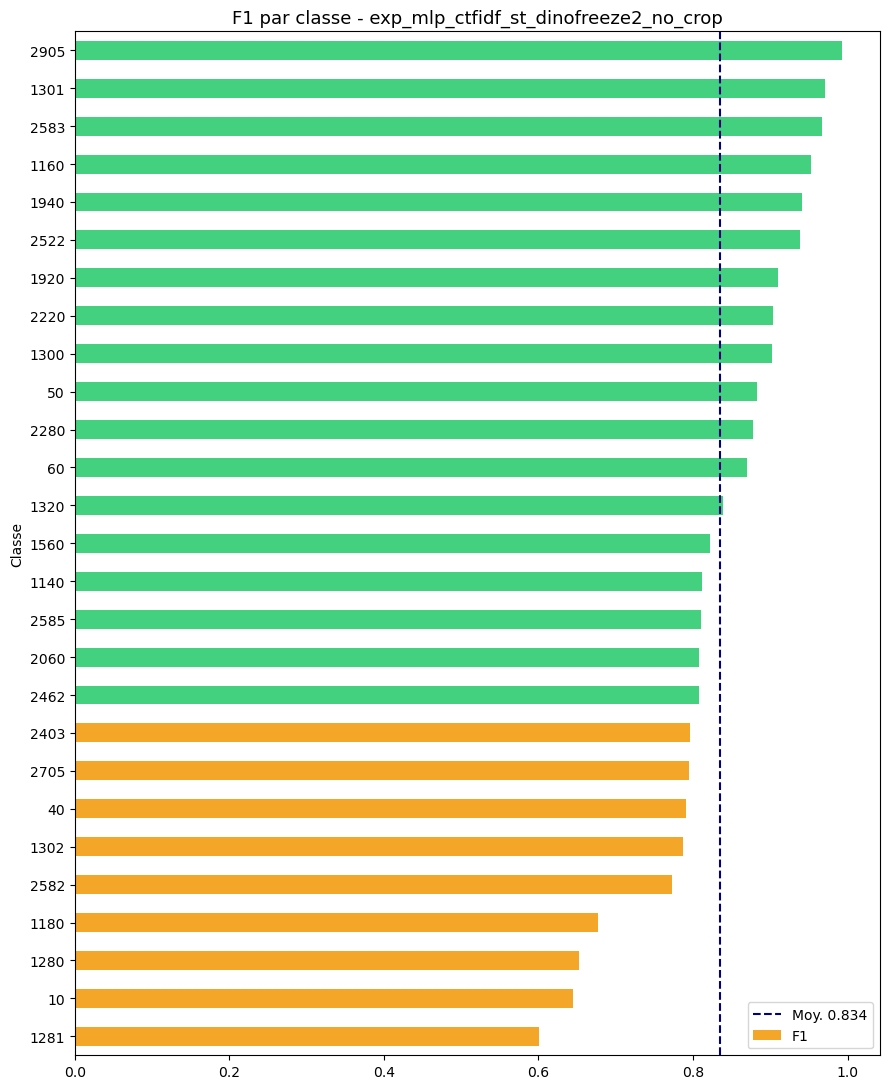

Classes F1 < 0.5 : []


In [67]:
f1_per = f1_score(y_test, preds_text_test, average=None)
df_f1  = pd.DataFrame({"Classe": class_names, "F1": f1_per})\
           .set_index("Classe").sort_values("F1")
colors = ["#E74C3C" if v<0.6 else "#F39C12" if v<0.8 else "#2ECC71"
          for v in df_f1["F1"]]
fig, ax = plt.subplots(figsize=(9, 11))
df_f1["F1"].plot(kind="barh", ax=ax, color=colors, alpha=0.9)
ax.axvline(df_f1["F1"].mean(), color="navy", linestyle="--",
           label=f"Moy. {df_f1['F1'].mean():.3f}")
ax.set_title(f"F1 par classe - {EXPERIMENT['name']}", fontsize=13)
ax.legend(); plt.tight_layout(); plt.show()
print(f"Classes F1 < 0.5 : {df_f1[df_f1['F1']<0.5].index.tolist()}")

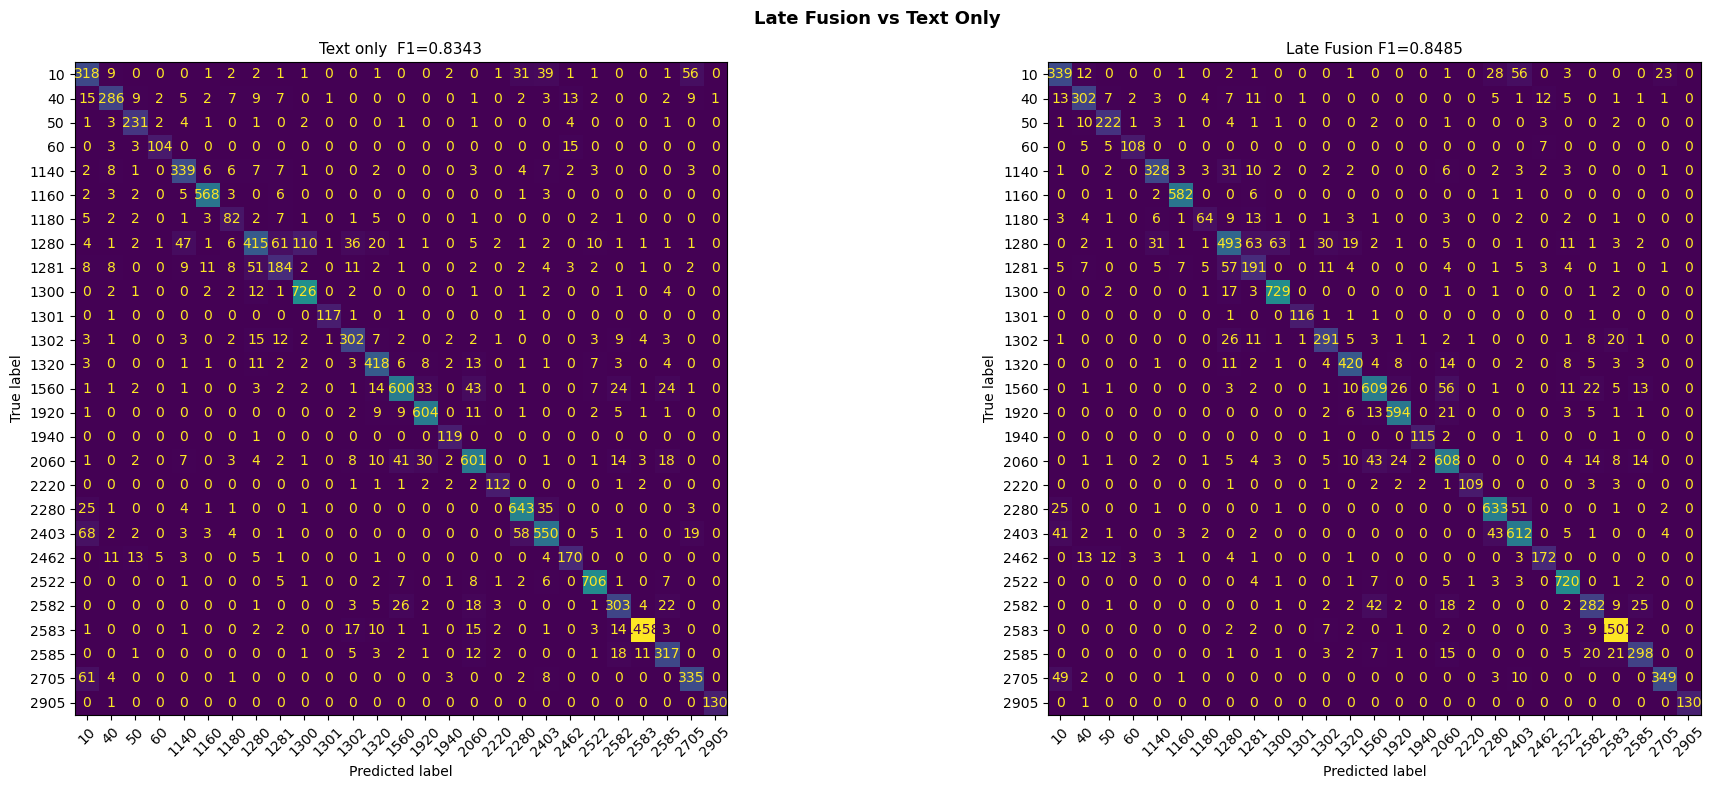

In [68]:
fig, axes = plt.subplots(1, 2, figsize=(20, 8))
for ax, (preds, title) in zip(axes, [
    (preds_text_test, f'Text only  F1={results["text_only"]:.4f}'),
    (preds_meta_test, f'Late Fusion F1={results["late_fusion (meta LogReg)"]:.4f}'),
]):
    cm = confusion_matrix(y_test, preds)
    ConfusionMatrixDisplay(cm, display_labels=[c[:8] for c in class_names]).plot(
        ax=ax, colorbar=False, xticks_rotation=45)
    ax.set_title(title, fontsize=11)
plt.suptitle('Late Fusion vs Text Only', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


In [69]:
# ══════════════════════════════════════════════════════════════════
# BENCHMARK GLOBAL — toutes les experiences de tous les notebooks
# ══════════════════════════════════════════════════════════════════
import glob, pandas as pd

csv_files = sorted(glob.glob(os.path.join(MODELS_DIR, 'experiments_*_results.csv')))
if not csv_files:
    print('Aucun CSV de resultats trouve dans', MODELS_DIR)
else:
    frames = []
    for f in csv_files:
        df = pd.read_csv(f)
        frames.append(df)

    df_all = pd.concat(frames, ignore_index=True)

    # Colonnes communes a tous les notebooks
    F1_COL  = next((c for c in ['F1 test','F1 macro test'] if c in df_all.columns), None)
    F1W_COL = next((c for c in ['F1w test','F1 weighted']  if c in df_all.columns), None)
    ACC_COL = next((c for c in ['Acc test','Accuracy test'] if c in df_all.columns), None)

    # Renommer pour uniformiser
    rename = {}
    if F1_COL  and F1_COL  != 'F1 test':  rename[F1_COL]  = 'F1 test'
    if F1W_COL and F1W_COL != 'F1w test': rename[F1W_COL] = 'F1w test'
    if ACC_COL and ACC_COL != 'Acc test': rename[ACC_COL] = 'Acc test'
    df_all = df_all.rename(columns=rename)

    # Colonne label : Experience + Strategie si dispo
    if 'Strategie' in df_all.columns:
        df_all['Modele'] = df_all['Experience'].fillna('') + ' / ' + df_all['Strategie'].fillna('')
    else:
        df_all['Modele'] = df_all['Experience'].fillna('')

    disp = ['Modele','F1 test','F1w test','Acc test']
    disp = [c for c in disp if c in df_all.columns]
    # Dedupliquer : garder le meilleur score par (Modele)
    df_bench = (df_all[disp].dropna(subset=['F1 test'])
                .sort_values('F1 test', ascending=False)
                .drop_duplicates(subset=['Modele'], keep='first')
                .reset_index(drop=True))

    print('' + '='*70)
    print('BENCHMARK GLOBAL')
    print('='*70)
    print(df_bench.to_string(index=True))
    print('='*70)
    print(f'Meilleur modele : {df_bench.iloc[0]["Modele"]}  F1={df_bench.iloc[0]["F1 test"]:.4f}')

    # Sauvegarde benchmark
    bench_path = os.path.join(MODELS_DIR, 'benchmark_global.csv')
    df_bench.to_csv(bench_path, index=False)
    print(f'Benchmark sauvegarde : {bench_path}')


BENCHMARK GLOBAL
                                                      Modele  F1 test  F1w test  Acc test
0            exp_mlp_ctfidf_st_dino_no_crop / avg_pond_a0.80   0.8550    0.8594    0.8614
1          exp_mlp_ctfidf_st_dino_no_crop / late_fusion_meta   0.8534    0.8615    0.8627
2                         exp_mlp_st_dino / late_fusion_meta   0.8529    0.8601    0.8612
3   exp_mlp_ctfidf_st_dinofreeze2_no_crop / late_fusion_meta   0.8485    0.8560    0.8570
4                  exp_latefusion_st_dino / late_fusion_meta   0.8480    0.8548    0.8549
5      exp_mlp_ctfidf_st_dinofreeze_no_crop / avg_pond_a0.75   0.8470    0.8523    0.8545
6     exp_mlp_ctfidf_st_dinofreeze2_no_crop / avg_pond_a0.70   0.8468    0.8517    0.8540
7                           exp_mlp_st_dino / avg_pond_a0.70   0.8437    0.8495    0.8519
8                    exp_latefusion_st_dino / avg_pond_a0.70   0.8433    0.8490    0.8514
9          exp_mlp_ctfidf_st_dinofreeze2_no_crop / text_only   0.8343    0.8416    

 exp_mlp_ctfidf_st_dino_no_crop : défreeze des dernieres couches dinov2 pour reentrainement